In [1]:
%pip install pygad


   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


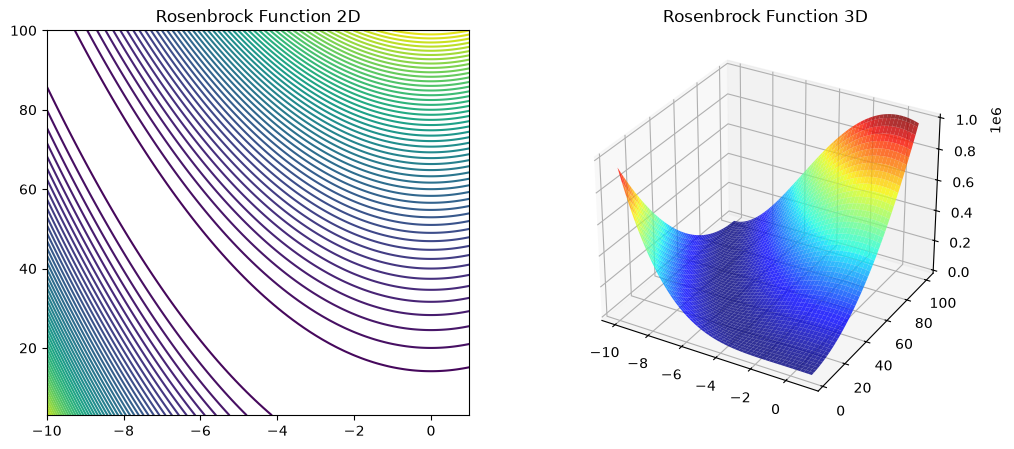

Initial guess [-0.61, 2.5], Result: [0.99999551 0.99999101], Value: 2.014569192114414e-11, Success: True, Iterations: 39, Time: 0.0113 sec
Initial guess [-1.6, 1.4], Result: [0.99999537 0.99999074], Value: 2.140422644036412e-11, Success: True, Iterations: 34, Time: 0.0089 sec
Initial guess [1.34, -1.5], Result: [0.99999864 0.99999747], Value: 5.521851931470222e-12, Success: False, Iterations: 35, Time: 0.0254 sec
PyGAD initial guess [-0.61, 2.5], Solution: [1.04616974 1.0979326 ], Value: 0.0033298234445543126, iterations: 100, Time: 0.0554 sec
PyGAD initial guess [-1.6, 1.4], Solution: [1.01340797 1.02994325], Value: 0.0010485746086633548, iterations: 100, Time: 0.0495 sec
PyGAD initial guess [1.34, -1.5], Solution: [0.90156087 0.80408916], Value: 0.01729906118783958, iterations: 100, Time: 0.0468 sec


c:\Users\Omen\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


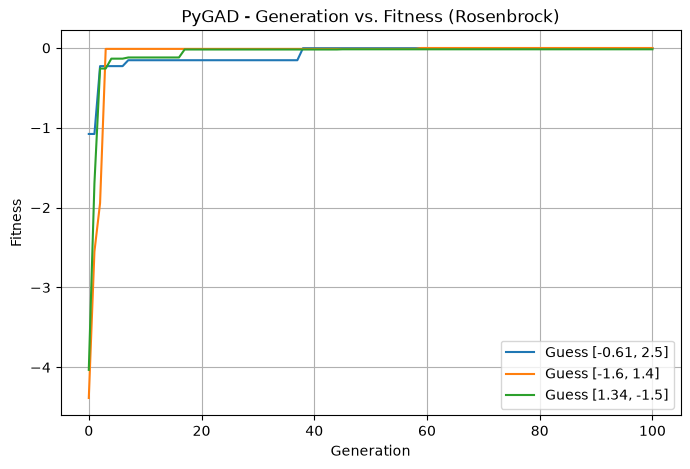

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (( 1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2)
# 2D & 3D plots
x_range = np.linspace(1, -10, 17650)
y_range = np.linspace(3, 100, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[-0.61, 2.5], [-1.6, 1.4], [1.34, -1.5]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate


pygad_fitness_history = []

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=100,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    
  
    pygad_fitness_history.append((guess, ga_instance.best_solutions_fitness))
    
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec")
    # ga_instance.plot_fitness() 


plt.figure(figsize=(8, 5))
for guess, fitness in pygad_fitness_history:
    plt.plot(fitness, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness (Rosenbrock)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True)
plt.show()

Q1 Answer : a. Changing the initial guess alters the minor decimal precision of the result, but all guesses successfully converge to the exact same region near [1.0, 1.0].It found the Global Minimum.

b.Changing the initial guess alters the the result, it does not find the exact solution. On increasing the number of iterations we near to the exact solution. As we increase the iterations the result obtained is the global minimum.

c.Comparing the two methods, SciPy's BFGS approach is much faster and more accurate, reaching extreme precision in just 34 to 39 steps. Meanwhile, the Genetic Algorithm (PyGAD) uses a trial-and-error population search; running it for 100 generations gets it much closer to the right answer, but it takes more time and lacks the precision.

Rosenbrock Function - The Rosenbrock function is a standard mathematical test function used to evaluate how effectively an optimization algorithm can find the lowest possible value. It features a characteristic long, narrow, and curved valley shaped like a banana. While optimization tools can easily find the general area of the valley, following its gentle slope down to the exact global minimum is very difficult, making it a benchmark for testing algorithm accuracy and performance.
For a two-dimensional case, the function is defined as: f(x, y) = (a - x)^2 + b(y - x^2)^2

BFGS - Gradient based method. Minimise is the function, for 1st method. PyGAD - Genetic

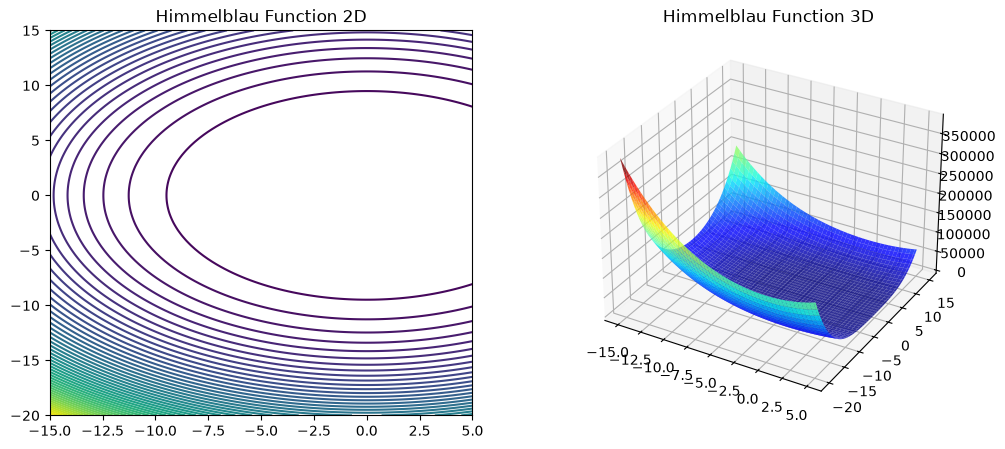

Initial guess [23, -3.5], Result: [ 1.00000011e+00 -2.01857639e-07], Value: 9.6287072595187e-14, Success: True, Iterations: 30, Time: 0.0105 sec
Initial guess [-6, 4], Result: [1.00000004e+00 2.34313648e-08], Value: 8.281574288561925e-15, Success: True, Iterations: 21, Time: 0.0065 sec
Initial guess [41, 10], Result: [1.00000001e+00 2.27057807e-09], Value: 1.0428952346134729e-15, Success: True, Iterations: 35, Time: 0.0138 sec
PyGAD initial guess [23, -3.5], Solution: [ 0.99876483 -0.00273221], Value: 1.5048854632768006e-05, Success: True, Iterations: 100, Time: 0.0854 sec
PyGAD initial guess [-6, 4], Solution: [0.99788718 0.00194404], Value: 2.6029787575726387e-05, Success: True, Iterations: 100, Time: 0.0756 sec
PyGAD initial guess [41, 10], Solution: [ 0.9921659  -0.00229794], Value: 0.00031006225156752045, Success: True, Iterations: 100, Time: 0.0865 sec


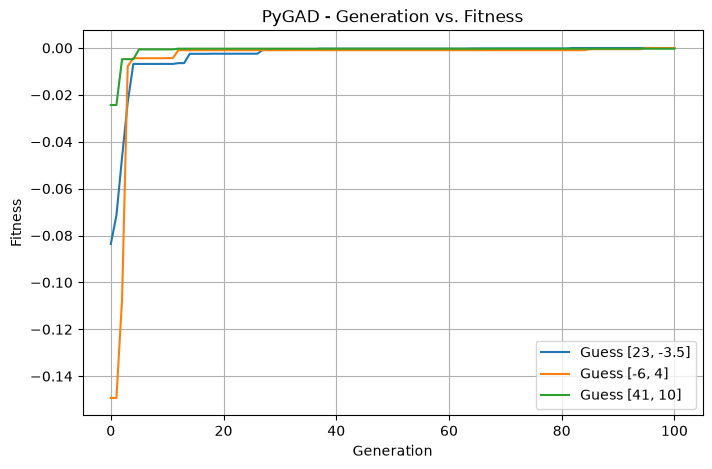

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad


def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + x[1]**2

# 2D & 3D plots
x_range = np.linspace(-15, 5, 100)
y_range = np.linspace(-20, 15, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()


elapsed_time = []

# Scipy Optimization
init_guesses = [[23, -3.50], [-6, 4], [41, 10]]
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)


pygad_fitness_history = []

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=100,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-1,
                           init_range_high=1,
                           gene_space={'low':-1, 'high':1})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    
    
    pygad_fitness_history.append((guess, ga_instance.best_solutions_fitness))
    
    #ga_instance.plot_fitness()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, Success: True, Iterations: {ga_instance.generations_completed}, Time: {elapsed_time:.4f} sec") 


plt.figure(figsize=(8, 5))
for guess, fitness in pygad_fitness_history:
    plt.plot(fitness, label=f"Guess {guess}")

plt.title("PyGAD - Generation vs. Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True)
plt.show()

Q 2 Answer : a.Changing the initial guesses results in minor decimal variations, but all guesses successfully converge to the exact same region near [1.0, 0.0].It found the Global Minimum.

b. Changing the initial guesses changes the solution a little bit. It found the Global Minimum.

c.Comparing the two methods, SciPy's BFGS approach is much faster and more accurate, reaching extreme precision in just 21 to 35 steps. Meanwhile, the Genetic Algorithm (PyGAD) relies on a trial-and-error population search; running it for 100 generations gets it reasonably close to the right answer, but it takes more time and lacks the precision of PyGAD.